In [1]:
import sys
print(sys.executable)

C:\Users\i-sht\OneDrive\Desktop\UrFU_project\.venv\Scripts\python.exe


In [2]:
# Основные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Загрузка данных
from ucimlrepo import fetch_ucirepo 

# **Первичный осмотр данных**

### 1. Смотрим на данные

In [23]:
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 
  
df = pd.concat([X, y], axis=1)

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


### 2. Информация по столбцам

Input variables:
   #### bank client data:
   1 - age (numeric)  
   2 - job : type of job (categorical: "admin.","unknown","unemployed","management","housemaid","entrepreneur","student",
                                       "blue-collar","self-employed","retired","technician","services")   
   3 - marital : marital status (categorical: "married","divorced","single"; note: "divorced" means divorced or widowed)  
   4 - education (categorical: "unknown","secondary","primary","tertiary")  
   5 - default: has credit in default? (binary: "yes","no")  
   6 - balance: average yearly balance, in euros (numeric)    
   7 - housing: has housing loan? (binary: "yes","no")  
   8 - loan: has personal loan? (binary: "yes","no")  
   #### related with the last contact of the current campaign:  
   9 - contact: contact communication type (categorical: "unknown","telephone","cellular")   
  10 - day: last contact day of the month (numeric)  
  11 - month: last contact month of year (categorical: "jan", "feb", "mar", ..., "nov", "dec")  
  12 - duration: last contact duration, in seconds (numeric)  
   #### other attributes:  
  13 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)  
  14 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric, -1 means client was not previously contacted)  
  15 - previous: number of contacts performed before this campaign and for this client (numeric)  
  16 - poutcome: outcome of the previous marketing campaign (categorical: "unknown","other","failure","success")  

  #### Output variable (desired target):  
  17 - y - has the client subscribed a term deposit? (binary: "yes","no")  



### 3. Оптимизируем память

In [24]:
memory_before = df.memory_usage(deep=True).sum()/1024**2
print(f"💾 Память до: {memory_before:.2f} MB")

💾 Память до: 24.56 MB


In [25]:
df.dtypes.value_counts()

str      10
int64     7
Name: count, dtype: int64

In [26]:
# Числовые типы
# выбрать атоматически
int_cols = df.select_dtypes(include=['int64']).columns
float_cols = df.select_dtypes(include=['float64']).columns

for col in int_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='integer')


# Замер памяти после оптимизации
memory_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"\n💾 Память после: {memory_after:.2f} MB")
print(f"📉 Экономия: {(1 - memory_after/memory_before)*100:.1f}%")


💾 Память после: 22.70 MB
📉 Экономия: 7.6%


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int8 
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int32
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int8 
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int16
 12  campaign     45211 non-null  int8 
 13  pdays        45211 non-null  int16
 14  previous     45211 non-null  int16
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int16(3), int32(1), int8(3), str(10)
memory usage: 4.0 MB


### 4. Статистика

In [28]:
df.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [29]:
df.describe(include='str')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,44923,45211,43354,45211,45211,45211,32191,45211,8252,45211
unique,11,3,3,2,2,2,2,12,3,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,failure,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,4901,39922


# **Качество данных**

### 1. Анализ пропусков

In [30]:
mis_count = df.isna().sum()
mis_pct = (df.isna().mean()*100).round(2)
mis_df = pd.DataFrame({'Пропуски':mis_count,
    'Процент':mis_pct}).query('Пропуски > 0').sort_values(by='Процент',ascending=False)
print("📊 Пропуски в данных:")
mis_df

📊 Пропуски в данных:


,Пропуски,Процент
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


### так как во всех столбцах есть категория unknown заполним пропуски этим значением

In [31]:
df[df['poutcome'].isna()]
df['poutcome'] = df['poutcome'].fillna('unknown')
df['contact'] = df['contact'].fillna('unknown')
df['education'] = df['education'].fillna('unknown')
df['job'] = df['job'].fillna('unknown')

In [32]:
mis_count = df[['poutcome','contact','education','job']].isna().sum()
mis_count

poutcome     0
contact      0
education    0
job          0
dtype: int64

### 2. Проверяем на выбросы

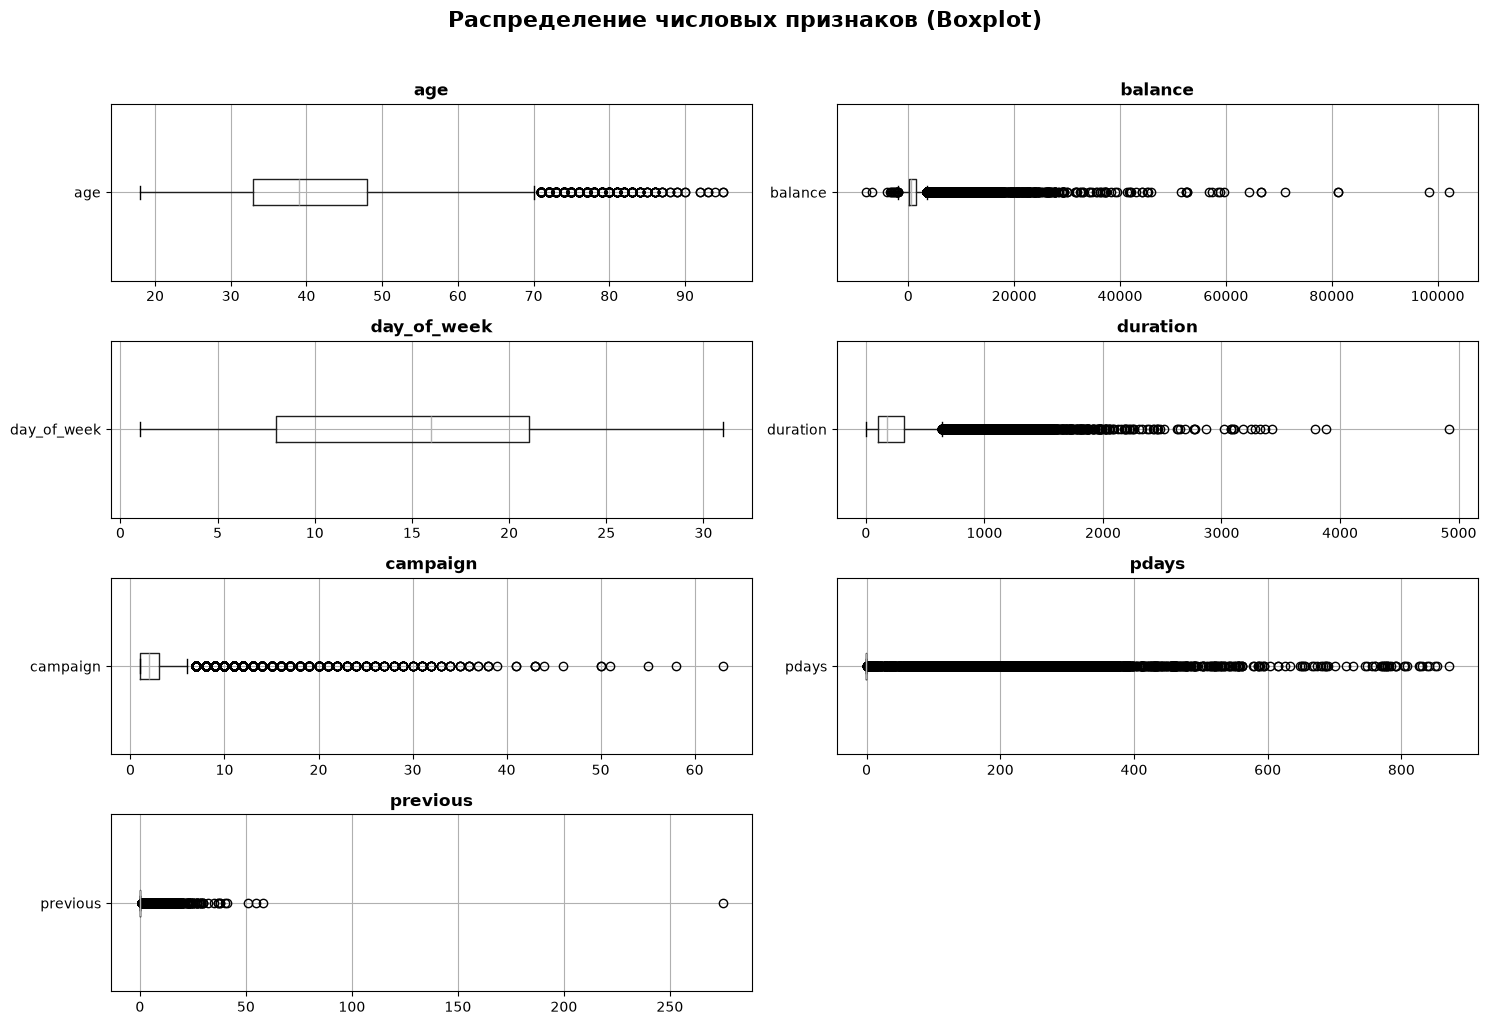

In [33]:
int_cols = ['age',	'balance',	'day_of_week',	'duration',	'campaign',	'pdays',	'previous']
fig,axes = plt.subplots(4,2,figsize=(15,10))
axes = axes.flatten()
axes[-1].set_visible(False)

for idx, col in enumerate(int_cols):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col,fontsize=12,fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение числовых признаков (Boxplot)', fontsize=16, fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

In [34]:
 # 1. balance — логарифмирование со знаком (сжимаем длинный хвост)
upper = df['balance'].quantile(0.99)
df['balance'] = np.clip(df['balance'], None, upper)

# 2. duration — Clipping по 99-му перцентилю
upper = df['duration'].quantile(0.99)
df['duration'] = np.clip(df['duration'], None, upper)

# 3. campaign — Clipping по 99-му перцентилю
upper = df['campaign'].quantile(0.99)
df['campaign'] = np.clip(df['campaign'], None, upper)

# 4. previous — Clipping по 99-му перцентилю
upper = df['previous'].quantile(0.99)
df['previous'] = np.clip(df['previous'], None, upper)

# 5. pdays — флаг + замена -1 на 0 (нейтральное значение)
df['was_contacted'] = (df['pdays'] != -1).astype(int)
df['pdays'] = df['pdays'].replace(-1, 0)

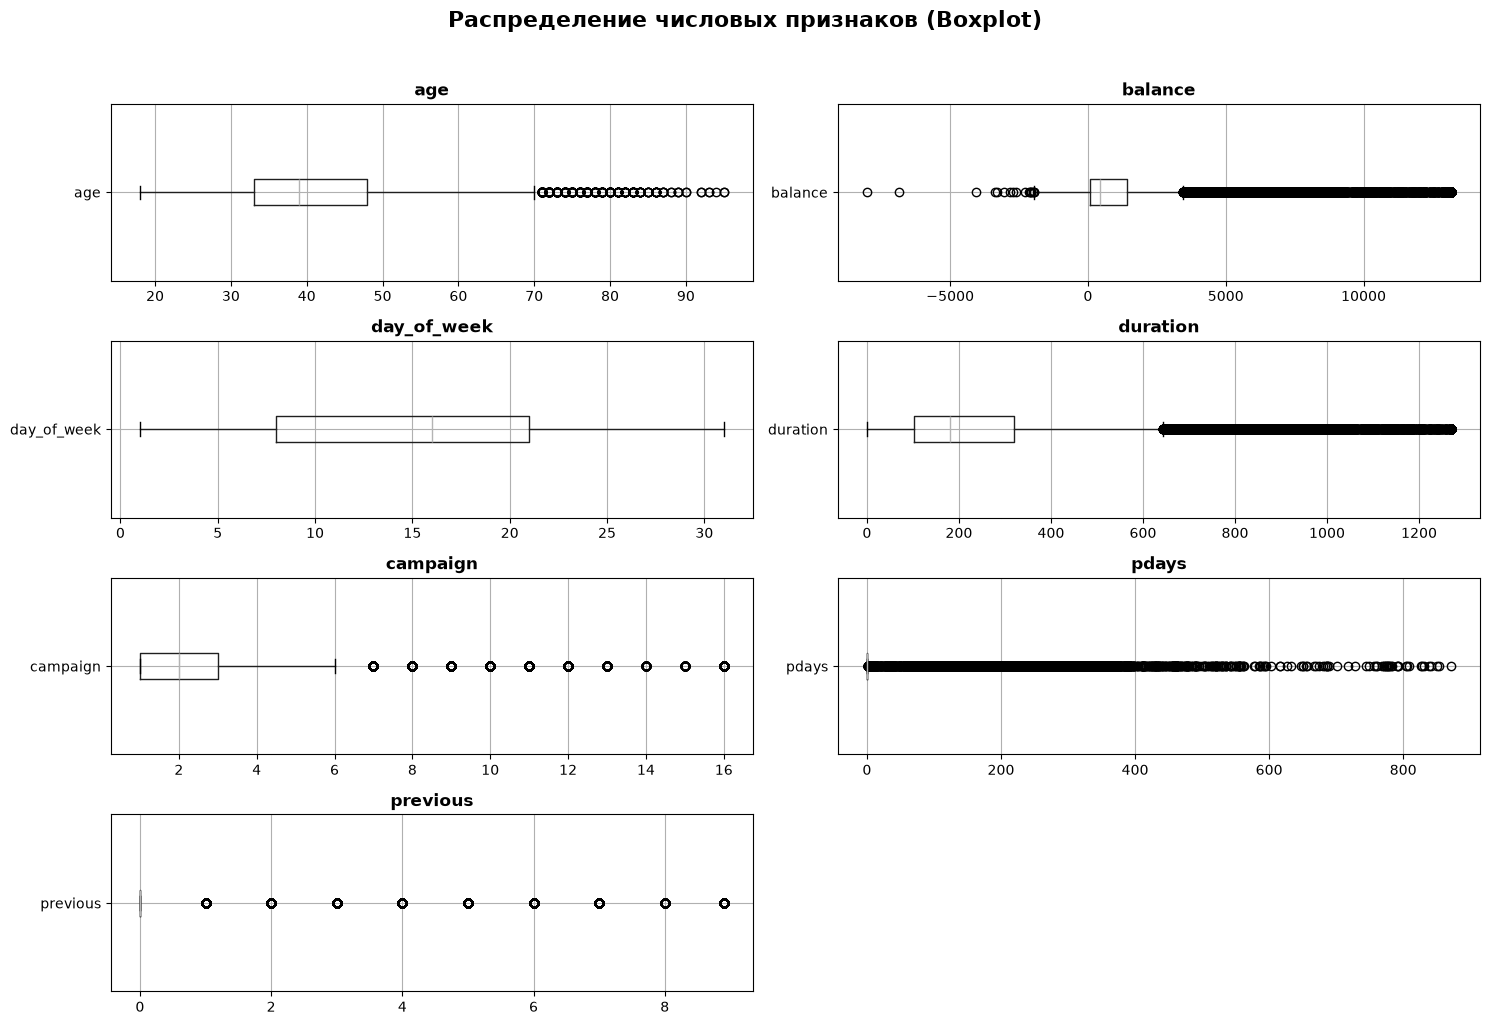

In [35]:
int_cols = ['age',	'balance',	'day_of_week',	'duration',	'campaign',	'pdays',	'previous']
fig,axes = plt.subplots(4,2,figsize=(15,10))
axes = axes.flatten()
axes[-1].set_visible(False)

for idx, col in enumerate(int_cols):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col,fontsize=12,fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение числовых признаков (Boxplot)', fontsize=16, fontweight='bold',y=1.02)
plt.tight_layout()
plt.show()

### **3. Анализ дубликатов**

In [36]:
# Полные дубликаты
full_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {full_duplicates:,} ({full_duplicates/len(df)*100:.2f}%)")

Полных дубликатов: 0 (0.00%)


# **Анализ признаков**

In [37]:
if "y" in df.columns:
    df = df.rename(columns={"y": "Y"})

# yes/no -> 1/0
df["Y"] = df["Y"].map({"yes": 1, "no": 0})
df['Y'].unique()

array([0, 1])

In [39]:
# Разделим признаки на категориальные и числовые
cat_cols = df.select_dtypes(include="str").columns.tolist()
num_cols = df.select_dtypes(include=np.number).columns.drop("Y").tolist()

print("Категориальные:", cat_cols)
print("Числовые:", num_cols)

Категориальные: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Числовые: ['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'was_contacted']


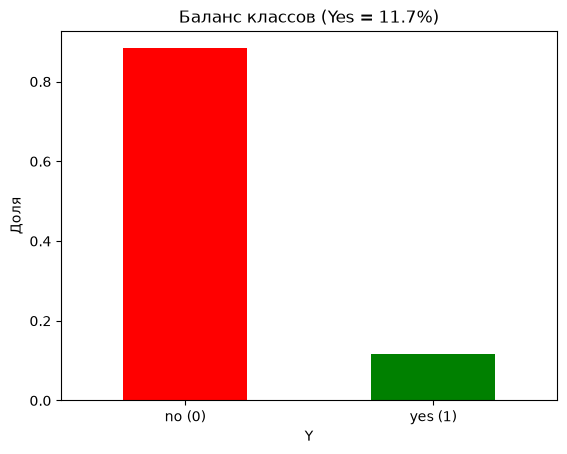

In [41]:
ax = df["Y"].value_counts(normalize=True).plot(kind="bar", color=["red", "green"])
ax.set_xticklabels(["no (0)", "yes (1)"], rotation=0)
ax.set_ylabel("Доля")
ax.set_title(f"Баланс классов (Yes = {df['Y'].mean()*100:.1f}%)")
plt.show()

In [47]:
!pip install scipy
from scipy.stats import shapiro, normaltest

for col in num_cols:
    stat, p = normaltest(df[col])  # тест Д'Агостино
    print(f"{col:10s}: p-value = {p:.2e}  -> {'НЕ нормально' if p < 0.05 else 'нормально'}")

age       : p-value = 0.00e+00  -> НЕ нормально
balance   : p-value = 0.00e+00  -> НЕ нормально
day_of_week: p-value = 0.00e+00  -> НЕ нормально
duration  : p-value = 0.00e+00  -> НЕ нормально
campaign  : p-value = 0.00e+00  -> НЕ нормально
pdays     : p-value = 0.00e+00  -> НЕ нормально
previous  : p-value = 0.00e+00  -> НЕ нормально
was_contacted: p-value = 0.00e+00  -> НЕ нормально


In [48]:
from scipy.stats import mannwhitneyu

def numeric_test(df, col, target="Y"):
    a = df.loc[df[target]==1, col]
    b = df.loc[df[target]==0, col]
    u, p_mw = mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 1 - (2*u)/(len(a)*len(b)) # Размер эффекта
    return {"feature": col, "mean_yes": a.mean(), "mean_no": b.mean(), 
            "p_value": p_mw, "effect_size": abs(r_rb)}

res_num = pd.DataFrame([numeric_test(df, c) for c in num_cols])
res_num.sort_values("p_value").round(4)

,feature,mean_yes,mean_no,p_value,effect_size
3,duration,518.8644,219.2999,0.0000,0.6152
6,previous,1.0928,0.4494,0.0000,0.2046
7,was_contacted,0.3602,0.1591,0.0000,0.2011
5,pdays,69.3428,37.2623,0.0000,0.1864
1,balance,1684.7036,1219.7624,0.0000,0.1801
4,campaign,2.1312,2.7656,0.0000,0.1447
2,day_of_week,15.1583,15.8923,0.0000,0.0530
0,age,41.6701,40.8390,0.0628,0.0157


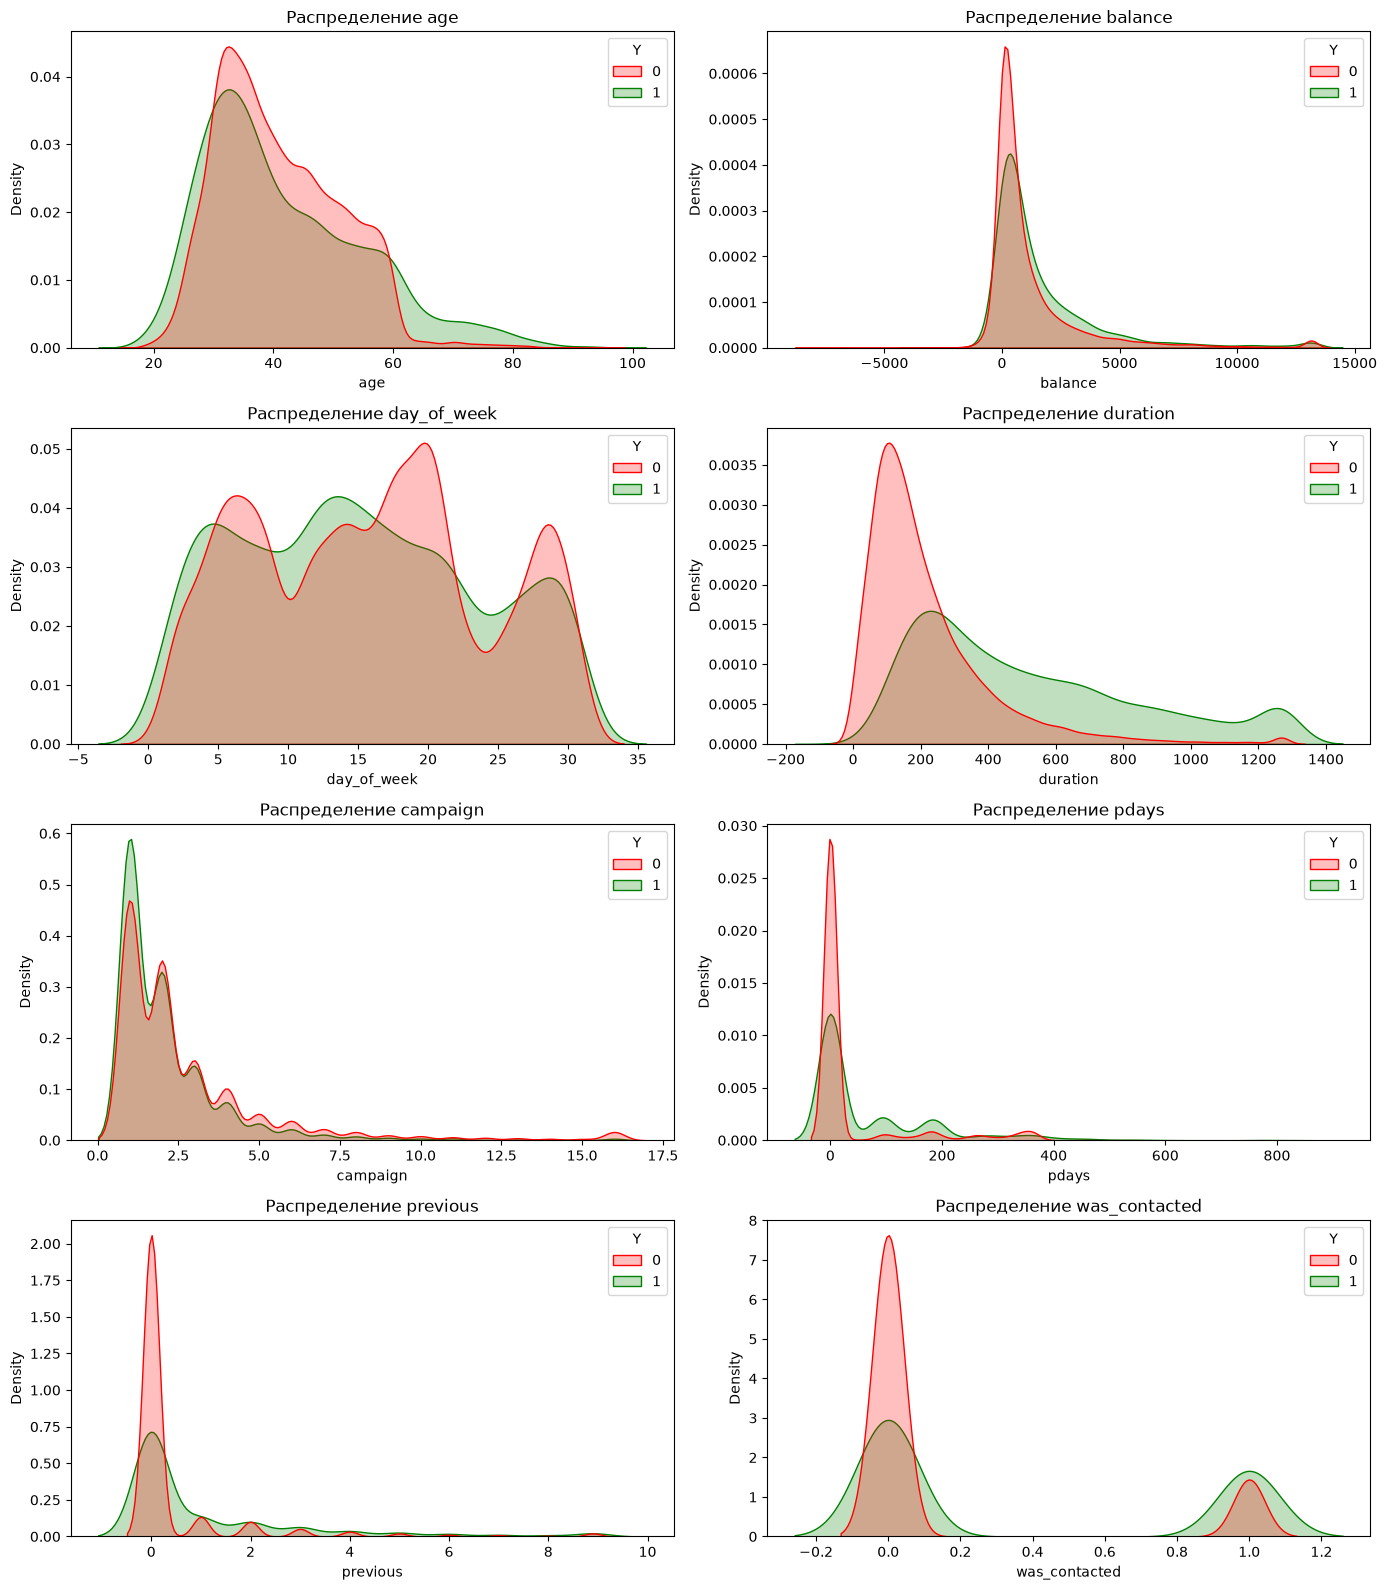

In [49]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    sns.kdeplot(data=df, x=col, hue="Y", common_norm=False, 
                fill=True, ax=axes[i], palette={0:"red", 1:"green"})
    axes[i].set_title(f"Распределение {col}")

plt.tight_layout()
plt.show()

In [54]:
def cat_test(df, col, target="Y"):
    ct = pd.crosstab(df[col], df[target])
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape)-1)))
    return {"feature": col, "p_value": p, "cramers_v": cramers_v}

res_cat = pd.DataFrame([cat_test(df, c) for c in cat_cols])
res_cat.sort_values("cramers_v", ascending=False).round(4)

,feature,p_value,cramers_v
8,poutcome,0.0,0.3117
7,month,0.0,0.2602
6,contact,0.0,0.1514
4,housing,0.0,0.1391
0,job,0.0,0.1360
2,education,0.0,0.0727
5,loan,0.0,0.0681
1,marital,0.0,0.0659
3,default,0.0,0.0222


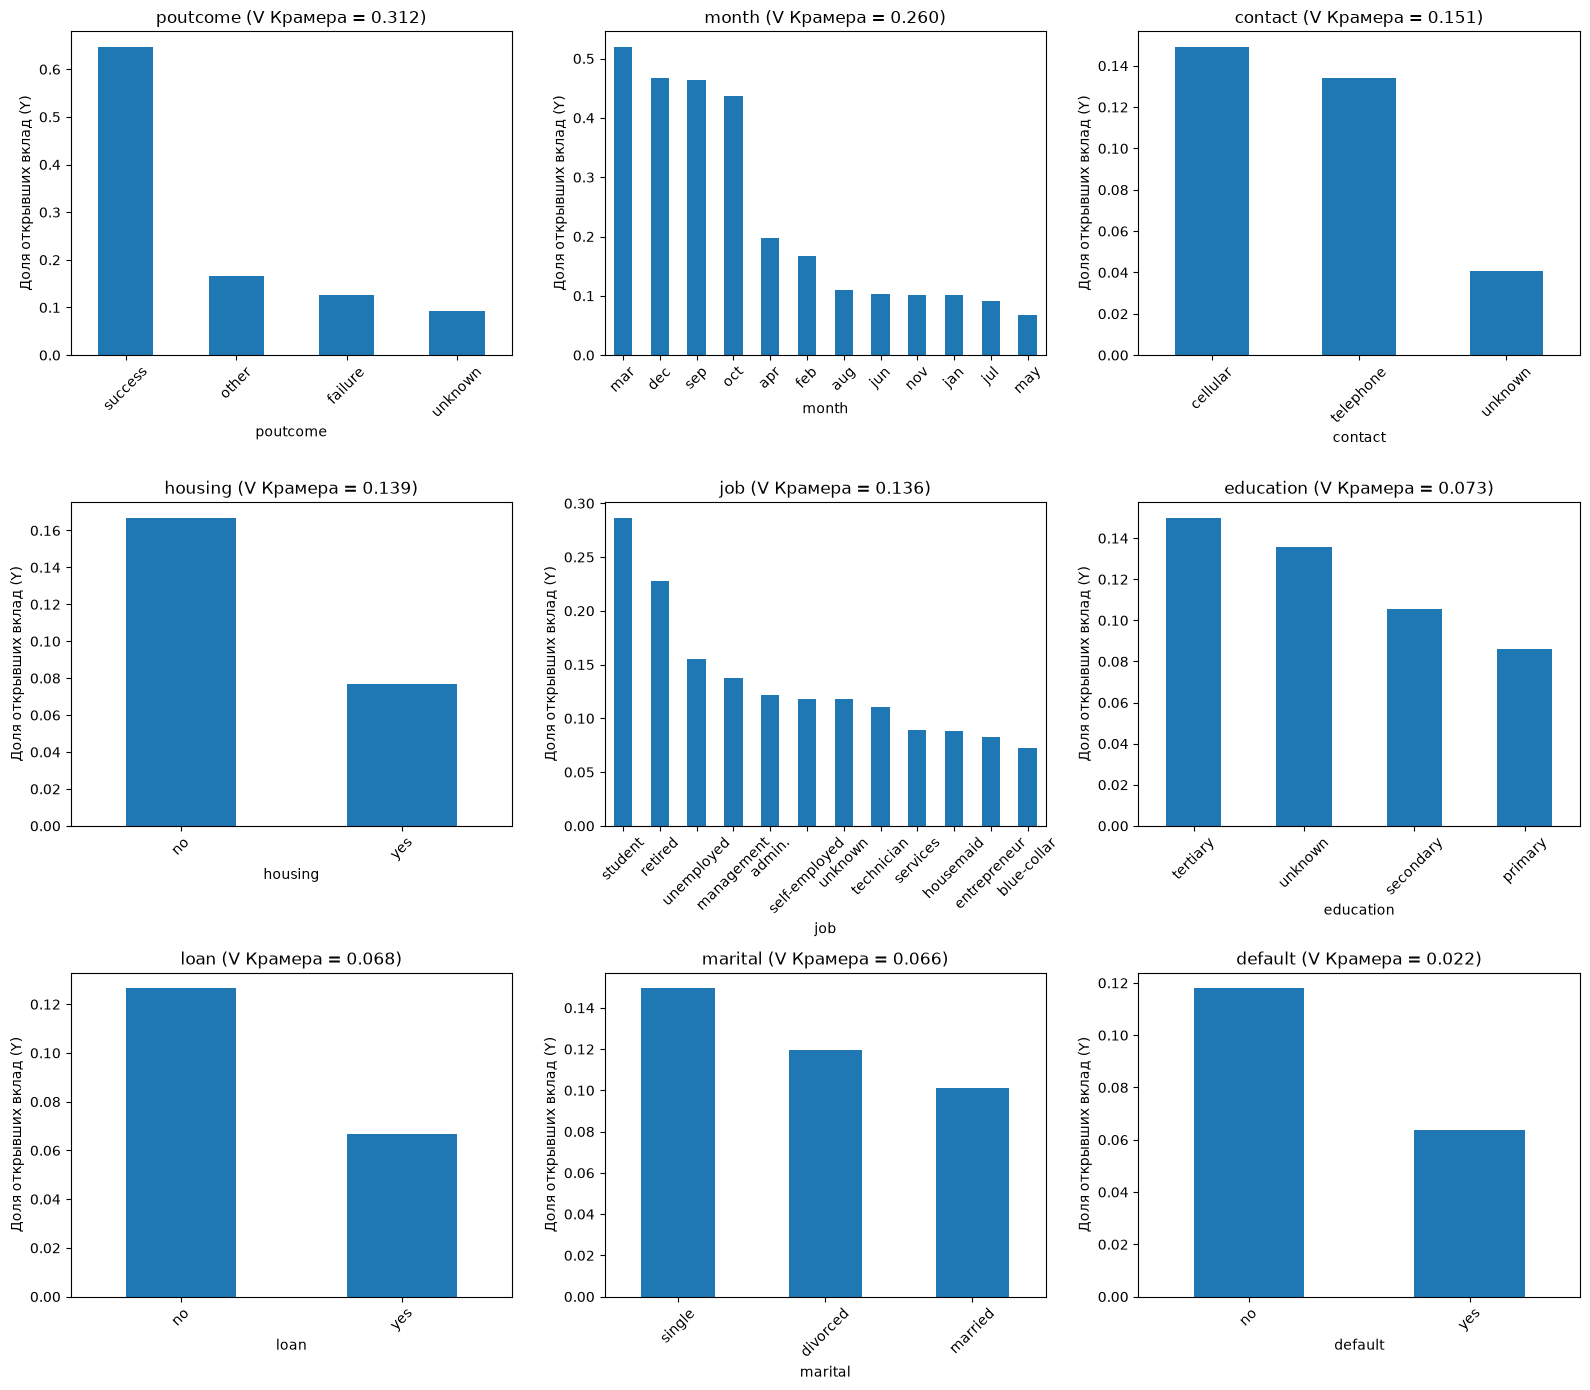

In [62]:
top_cats = res_cat.sort_values("cramers_v", ascending=False)["feature"]

fig, axes = plt.subplots(3, 3, figsize=(16, 14))
axes = axes.ravel()

for i, col in enumerate(top_cats):
    # Считаем долю 'yes' для каждой категории
    tmp = df.groupby(col)["Y"].mean().sort_values(ascending=False)
        
    tmp.plot(kind="bar", ax=axes[i])
    v_score = res_cat.set_index('feature').loc[col, 'cramers_v']
    axes[i].set_title(f"{col} (V Крамера = {v_score:.3f})")
    axes[i].set_ylabel("Доля открывших вклад (Y)")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

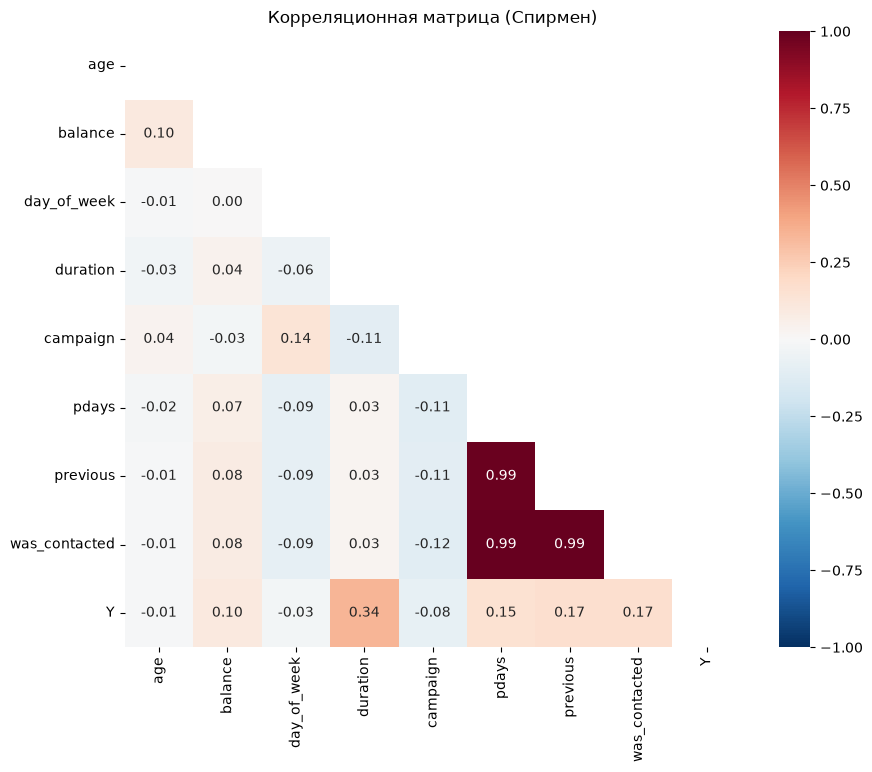

In [57]:
plt.figure(figsize=(10, 8))
corr = df[num_cols + ["Y"]].corr(method="spearman") # Спирмен устойчив к выбросам
mask = np.triu(np.ones_like(corr, dtype=bool)) # Прячем верхний треугольник

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", 
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Корреляционная матрица (Спирмен)")
plt.show()

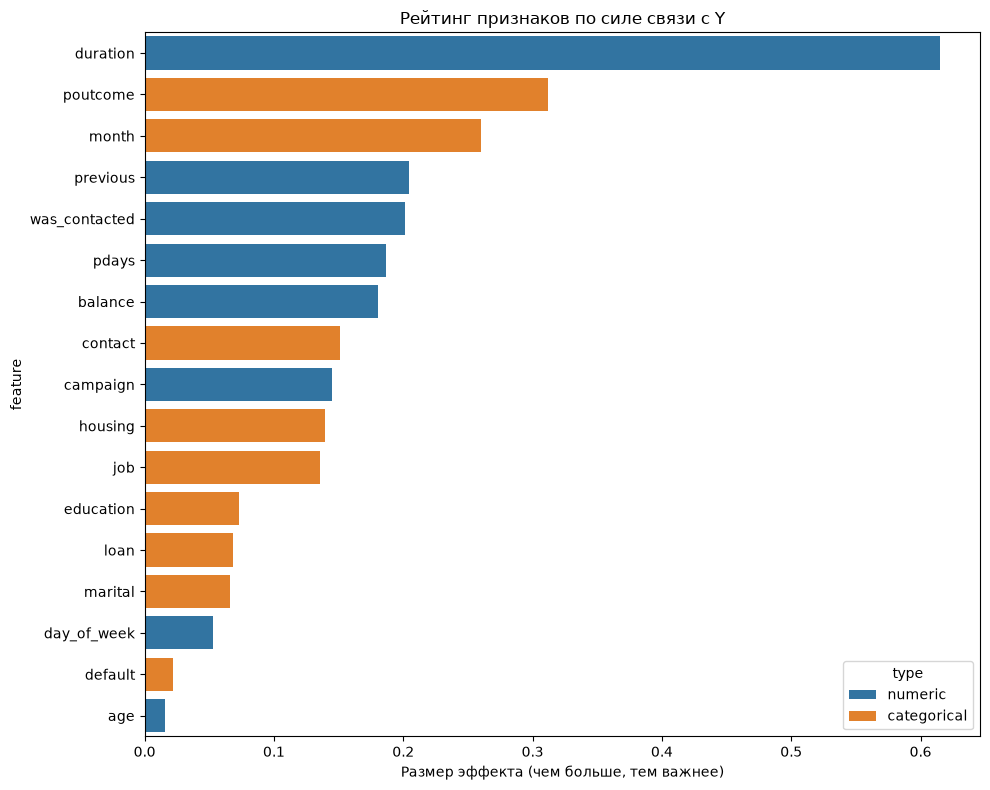

In [63]:
summary = []
for _, row in res_num.iterrows():
    summary.append({"feature": row["feature"], "type": "numeric", "score": row["effect_size"], "metric": "Mann-Whitney"})
    
for _, row in res_cat.iterrows():
    summary.append({"feature": row["feature"], "type": "categorical", "score": row["cramers_v"], "metric": "Cramer's V"})

summary_df = pd.DataFrame(summary).sort_values("score", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=summary_df, y="feature", x="score", hue="type", dodge=False)
plt.title("Рейтинг признаков по силе связи с Y")
plt.xlabel("Размер эффекта (чем больше, тем важнее)")
plt.tight_layout()
plt.show()

# Таким образом мы видим какие признаки влияют на таргет сильнее всего, а выше мы также можно видеть распределение по категориям и числам внутри признаков